# Practical Application III: Comparing Classifiers



### Overview

In this practical application, your goal is to compare the performance of the classifiers we encountered in this section, namely K Nearest Neighbor, Logistic Regression, Decision Trees, and Support Vector Machines.  We will utilize a dataset related to marketing bank products over the telephone.

### Getting Started

Our dataset comes from the UCI Machine Learning repository [link](https://archive.ics.uci.edu/ml/datasets/bank+marketing).  The data is from a Portugese banking institution and is a collection of the results of multiple marketing campaigns.  We will make use of the article accompanying the dataset [here](CRISP-DM-BANK.pdf) for more information on the data and features.



# Import Libraries

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper.  How many marketing campaigns does this data represent?

**Answer:** According to the paper, this data represents 17 campaigns.

# Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and assign to a meaningful variable name.

In [14]:
# Read Data
df = pd.read_csv('/content/bank-additional-full.csv', sep=';') #CSV included in repository, code setup to read data from Google Drive.

# Dataset Shape
print("Dataset shape:", df.shape)

# Preview Data
display(df.head())

Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


# Problem 3: Understanding the Features


Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.


```
Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')
3 - marital : marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)
4 - education (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')
# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')
10 - day_of_week: last contact day of the week (categorical: 'mon','tue','wed','thu','fri')
11 - duration: last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
# other attributes:
12 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
13 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)
14 - previous: number of contacts performed before this campaign and for this client (numeric)
15 - poutcome: outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')
# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator (numeric)
17 - cons.price.idx: consumer price index - monthly indicator (numeric)
18 - cons.conf.idx: consumer confidence index - monthly indicator (numeric)
19 - euribor3m: euribor 3 month rate - daily indicator (numeric)
20 - nr.employed: number of employees - quarterly indicator (numeric)

Output variable (desired target):
21 - y - has the client subscribed a term deposit? (binary: 'yes','no')
```


In [15]:
# Examine columns, data types, and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

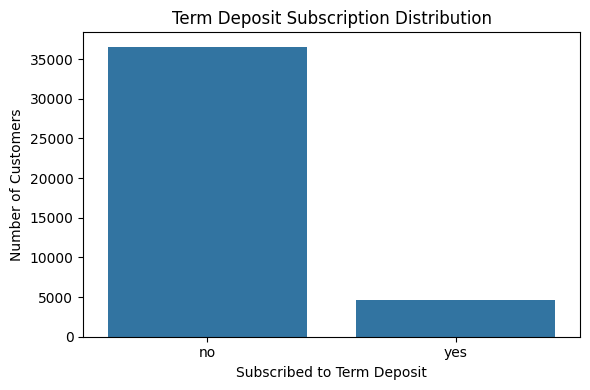

In [55]:
# Visualize target distribution
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x='y',
    order=['no', 'yes']
)

plt.title('Term Deposit Subscription Distribution')
plt.xlabel('Subscribed to Term Deposit')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

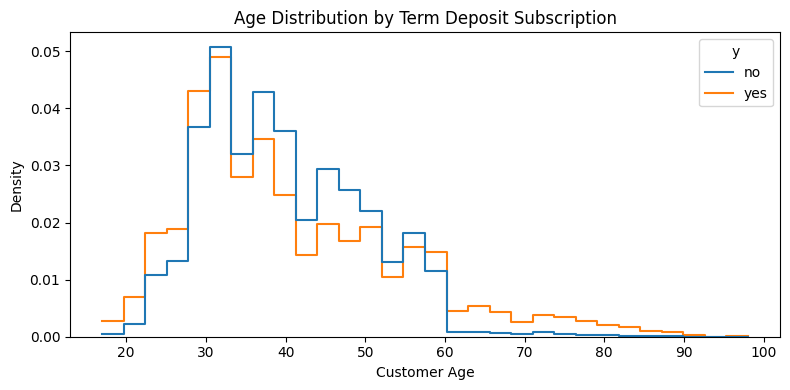

In [56]:
# Visualize age distribution by subscription
plt.figure(figsize=(8, 4))

sns.histplot(
    data=df,
    x='age',
    hue='y',
    bins=30,
    stat='density',
    common_norm=False,
    element='step',
    fill=False
)

plt.title('Age Distribution by Term Deposit Subscription')
plt.xlabel('Customer Age')
plt.ylabel('Density')

plt.tight_layout()
plt.show()

In [57]:
# Summarize customer age by subscription status
display(
    df.groupby('y')['age']
      .describe()
      .round(2)
)

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,36548.0,39.91,9.90,17.0,32.0,38.0,47.0,95.0
yes,4640.0,40.91,13.84,17.0,31.0,37.0,50.0,98.0


**Answer:** The dataset contains 21 columns, consisting of 20 input features and one binary target variable. The input features include customer demographics, marketing campaign information, and social and economic indicators. After examining the data types, I determined that the numerical and categorical variables are appropriately classified. Integer data types (`int64`) are appropriate for age and count-based variables, floating-point data types (`float64`) are appropriate for continuous numerical indicators, and object data types are appropriate for categorical variables. No conventional null values were identified in the dataset.

# Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task.  State the objective below.

**Answer:** The business objective is to develop machine learning models that can predict whether a customer will subscribe to a term deposit following a marketing campaign. The bank hopes to identify customers who are more likely to subscribe by analyzing customer characteristics and financial information. These predictions could help the bank reduce marketing and labor costs while maximizing the effectiveness of its outreach efforts.

# Problem 5: Engineering Features

In [16]:
# Select bank information features
bank_features = [
    'age',
    'job',
    'marital',
    'education',
    'default',
    'housing',
    'loan'
]

# Assign X and y values
X = df[bank_features]
y = df['y']

In [17]:
# Identify categorical features
categorical_features = [
    'job',
    'marital',
    'education',
    'default',
    'housing',
    'loan'
]

# Apply one-hot encoding
X = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

# Encode target variable
y = y.map({'no': 0, 'yes': 1})

In [18]:
# Verify the correct number of encoded columns was created
expected_columns = (
    df[categorical_features].nunique().sub(1).sum() + 1 # Count unique values, subtract 1 due to drop_first above, count values, then add one for the numerical age feature
)

assert expected_columns == X.shape[1], "Column count mismatch!" #Error message

print("Expected encoded columns:", expected_columns)
print("Actual encoded columns:", X.shape[1])

Expected encoded columns: 28
Actual encoded columns: 28


In [19]:
# Examine the encoded features and target
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nEncoded features:")
display(X.head())

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (41188, 28)
Target shape: (41188,)

Encoded features:


,age,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,...,education_illiterate,education_professional.course,education_university.degree,education_unknown,default_unknown,default_yes,housing_unknown,housing_yes,loan_unknown,loan_yes
0,56,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,57,0,0,0,0,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,0
2,37,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
3,40,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,56,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,1



Target distribution:
y
0    36548
1     4640
Name: count, dtype: int64


# Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

In [20]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=10,
    stratify=y
)

In [21]:
# Examine training and testing set dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (32950, 28)
Testing features: (8238, 28)

Training target: (32950,)
Testing target: (8238,)


In [22]:
# Compare target distributions
print("Training target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training target distribution:
y
0    0.887344
1    0.112656
Name: proportion, dtype: float64

Testing target distribution:
y
0    0.887351
1    0.112649
Name: proportion, dtype: float64


# Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline.  What is the baseline performance that our classifier should aim to beat?

In [23]:
# Create baseline model
baseline_model = DummyClassifier(strategy='most_frequent')

# Train baseline model
baseline_model.fit(X_train, y_train)

# Generate predictions
baseline_predictions = baseline_model.predict(X_test)

# Evaluate baseline accuracy
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print("Baseline Accuracy:", baseline_accuracy)

Baseline Accuracy: 0.8873512988589464


# Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.  

In [24]:
# Create Logistic Regression model
logistic_model = LogisticRegression(
    random_state=10,
    max_iter=1000
)

# Train the model
logistic_model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=10)

# Problem 9: Score the Model

What is the accuracy of your model?

In [25]:
# Generate predictions using test data
logistic_predictions = logistic_model.predict(X_test)

In [26]:
# Evaluate model accuracy
logistic_accuracy = accuracy_score(y_test, logistic_predictions)

print("Logistic Regression Accuracy:", logistic_accuracy)

Logistic Regression Accuracy: 0.8873512988589464


# Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models.  Using the default settings for each of the models, fit and score each.  Also, be sure to compare the fit time of each of the models.  Present your findings in a `DataFrame` similar to that below:

| Model | Train Time | Train Accuracy | Test Accuracy |
| ----- | ---------- | -------------  | -----------   |
|     |    |.     |.     |

#### Train the Default Classifiers

In [27]:
# Create KNN model
knn_model = KNeighborsClassifier()

# Measure training time
start_time = time.perf_counter()

knn_model.fit(X_train, y_train)

knn_train_time = time.perf_counter() - start_time

print(f"KNN Training Time: {knn_train_time:.4f} seconds")

KNN Training Time: 0.0264 seconds


In [28]:
# Create Decision Tree model
tree_model = DecisionTreeClassifier(random_state=10)

# Measure training time
start_time = time.perf_counter()

tree_model.fit(X_train, y_train)

tree_train_time = time.perf_counter() - start_time

print(f"Decision Tree Training Time: {tree_train_time:.4f} seconds")

Decision Tree Training Time: 0.3703 seconds


In [29]:
# Create SVM model
svm_model = SVC()

# Measure training time
start_time = time.perf_counter()

svm_model.fit(X_train, y_train)

svm_train_time = time.perf_counter() - start_time

print(f"SVM Training Time: {svm_train_time:.4f} seconds")

SVM Training Time: 15.8249 seconds


In [30]:
# Measure Logistic Regression training time
start_time = time.perf_counter()

logistic_model.fit(X_train, y_train)

logistic_train_time = time.perf_counter() - start_time

#### Compare Model Performance

In [31]:
# Calculate training and testing accuracy

models = {
    'Logistic Regression': logistic_model,
    'KNN': knn_model,
    'Decision Tree': tree_model,
    'SVM': svm_model
}

results = []

for name, model in models.items():

    # Generate predictions
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    # Calculate accuracy
    train_accuracy = accuracy_score(y_train, train_predictions)
    test_accuracy = accuracy_score(y_test, test_predictions)

    results.append({
        'Model': name,
        'Train Accuracy': train_accuracy,
        'Test Accuracy': test_accuracy
    })

In [32]:
# Create model comparison DataFrame
comparison_df = pd.DataFrame(results)

# Add training times
training_times = {
    'Logistic Regression': logistic_train_time,
    'KNN': knn_train_time,
    'Decision Tree': tree_train_time,
    'SVM': svm_train_time
}

comparison_df['Train Time'] = comparison_df['Model'].map(training_times)

# Organize columns
comparison_df = comparison_df[
    ['Model', 'Train Time', 'Train Accuracy', 'Test Accuracy']
]

# Display results
display(comparison_df.round(4))

,Model,Train Time,Train Accuracy,Test Accuracy
0,Logistic Regression,1.7487,0.8873,0.8874
1,KNN,0.0264,0.8910,0.8758
2,Decision Tree,0.3703,0.9166,0.8691
3,SVM,15.8249,0.8873,0.8874


# Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these.  Below, we list a few things to explore in this pursuit.


- Hyperparameter tuning and grid search.  All of our models have additional hyperparameters to tune and explore.  For example the number of neighbors in KNN or the maximum depth of a Decision Tree.  
- Adjust your performance metric

#### Evaluate Baseline and Original Models

In [33]:
# Organize models for evaluation
baseline_models = {
    'Baseline': baseline_model,
    'Logistic Regression': logistic_model,
    'KNN': knn_model,
    'Decision Tree': tree_model,
    'SVM': svm_model
}

# Store evaluation results
evaluation_results = []

# Evaluate each model
for name, model in baseline_models.items():

    # Generate predictions
    predictions = model.predict(X_test)

    # Calculate performance metrics
    evaluation_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1-Score': f1_score(y_test, predictions, zero_division=0)
    })

# Create comparison DataFrame
baseline_metrics = pd.DataFrame(evaluation_results)

# Display results
display(baseline_metrics.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Baseline,0.8874,0.0000,0.0000,0.0000
1,Logistic Regression,0.8874,0.0000,0.0000,0.0000
2,KNN,0.8758,0.2907,0.0711,0.1143
3,Decision Tree,0.8691,0.2807,0.1034,0.1512
4,SVM,0.8874,0.0000,0.0000,0.0000


In [34]:
# Examine predicted class distributions

for name, model in baseline_models.items():

    predictions = model.predict(X_test)

    print(f"\n{name}")
    print(predictions.value_counts() if isinstance(predictions, pd.Series)
          else pd.Series(predictions).value_counts())


Baseline
0    8238
Name: count, dtype: int64

Logistic Regression
0    8238
Name: count, dtype: int64

KNN
0    8011
1     227
Name: count, dtype: int64

Decision Tree
0    7896
1     342
Name: count, dtype: int64

SVM
0    8238
Name: count, dtype: int64


In [35]:
# Baseline Confusion Matrix
for name, model in baseline_models.items():

    predictions = model.predict(X_test)

    print(f"\n{name}")
    print(confusion_matrix(y_test, predictions))


Baseline
[[7310    0]
 [ 928    0]]

Logistic Regression
[[7310    0]
 [ 928    0]]

KNN
[[7149  161]
 [ 862   66]]

Decision Tree
[[7064  246]
 [ 832   96]]

SVM
[[7310    0]
 [ 928    0]]


#### Explore Logistic Regression Decision Thresholds

In [36]:
# Examine Logistic Regression probabilities
positive_probabilities = logistic_model.predict_proba(X_test)[:, 1]

print("Minimum probability:", positive_probabilities.min())
print("Maximum probability:", positive_probabilities.max())
print("Average probability:", positive_probabilities.mean())

print("\nProbability percentiles:")
print(np.percentile(positive_probabilities, [25, 50, 75, 90, 95, 99]))

Minimum probability: 0.022652652399775805
Maximum probability: 0.4571671810939548
Average probability: 0.11275747269745506

Probability percentiles:
[0.07732846 0.10733381 0.13613161 0.16519413 0.2193703  0.34158232]


In [37]:
# Examine Logistic Regression at different thresholds

for threshold in [0.50, 0.30, 0.20, 0.10]:

    predictions = (
        positive_probabilities >= threshold
    ).astype(int)

    print(f"\nThreshold: {threshold}")

    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions, zero_division=0))
    print("Recall:", recall_score(y_test, predictions, zero_division=0))
    print("F1-score:", f1_score(y_test, predictions, zero_division=0))


Threshold: 0.5
Accuracy: 0.8873512988589464
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Threshold: 0.3
Accuracy: 0.8773974265598447
Precision: 0.3247863247863248
Recall: 0.08189655172413793
F1-score: 0.13080895008605853

Threshold: 0.2
Accuracy: 0.8640446710366594
Precision: 0.2894736842105263
Recall: 0.14224137931034483
F1-score: 0.1907514450867052

Threshold: 0.1
Accuracy: 0.4845836368050498
Precision: 0.14505776636713735
Recall: 0.7306034482758621
F1-score: 0.2420564084255623


#### Evaluate Feature Scaling

In [38]:
# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), ['age'])
    ],
    remainder='passthrough'
)

# Create Logistic Regression pipeline
scaled_logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        random_state=10,
        max_iter=1000
    ))
])

# Train scaled Logistic Regression model
scaled_logistic_model.fit(X_train, y_train)

# Generate predictions
scaled_logistic_predictions = scaled_logistic_model.predict(X_test)

# Evaluate model performance
scaled_logistic_accuracy = accuracy_score(y_test, scaled_logistic_predictions)
scaled_logistic_precision = precision_score(y_test, scaled_logistic_predictions, zero_division=0)
scaled_logistic_recall = recall_score(y_test, scaled_logistic_predictions, zero_division=0)
scaled_logistic_f1 = f1_score(y_test, scaled_logistic_predictions, zero_division=0)

# Display results
print("Scaled Logistic Regression Results")
print("----------------------------------")
print("Accuracy:", scaled_logistic_accuracy)
print("Precision:", scaled_logistic_precision)
print("Recall:", scaled_logistic_recall)
print("F1-score:", scaled_logistic_f1)

Scaled Logistic Regression Results
----------------------------------
Accuracy: 0.8873512988589464
Precision: 0.0
Recall: 0.0
F1-score: 0.0


#### Address Class Imbalance

In [39]:
# Create balanced Logistic Regression pipeline
balanced_logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        random_state=10,
        max_iter=1000,
        class_weight='balanced'
    ))
])

# Train balanced Logistic Regression model
balanced_logistic_model.fit(X_train, y_train)

# Generate predictions
balanced_logistic_predictions = balanced_logistic_model.predict(X_test)

# Evaluate model performance
balanced_logistic_accuracy = accuracy_score(
    y_test, balanced_logistic_predictions
)

balanced_logistic_precision = precision_score(
    y_test, balanced_logistic_predictions, zero_division=0
)

balanced_logistic_recall = recall_score(
    y_test, balanced_logistic_predictions, zero_division=0
)

balanced_logistic_f1 = f1_score(
    y_test, balanced_logistic_predictions, zero_division=0
)

# Display results
print("Balanced Logistic Regression Results")
print("-------------------------------------")
print("Accuracy:", balanced_logistic_accuracy)
print("Precision:", balanced_logistic_precision)
print("Recall:", balanced_logistic_recall)
print("F1-score:", balanced_logistic_f1)

Balanced Logistic Regression Results
-------------------------------------
Accuracy: 0.5867929109007041
Precision: 0.1580110497237569
Recall: 0.6163793103448276
F1-score: 0.2515391380826737


In [40]:
# Examine balanced Logistic Regression predictions
print(confusion_matrix(y_test, balanced_logistic_predictions))

[[4262 3048]
 [ 356  572]]


#### Tune Logistic Regression

In [41]:
# Define Logistic Regression pipeline
logistic_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        random_state=10,
        max_iter=1000
    ))
])

# Define hyperparameter search space
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__class_weight': [None, 'balanced']
}

# Configure Grid Search
logistic_grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

# Fit Grid Search using training data
logistic_grid_search.fit(X_train, y_train)

# Display best hyperparameters
print("Best Parameters:", logistic_grid_search.best_params_)

print("\nBest Cross-Validation F1-score:")
print(logistic_grid_search.best_score_)

Best Parameters: {'classifier__C': 100, 'classifier__class_weight': 'balanced'}

Best Cross-Validation F1-score:
0.25574458325765004


In [42]:
# Examine all Grid Search results
grid_results = pd.DataFrame(logistic_grid_search.cv_results_)

display(
    grid_results[
        ['param_classifier__C',
         'param_classifier__class_weight',
         'mean_test_score',
         'std_test_score']
    ].sort_values('mean_test_score', ascending=False)
)

,param_classifier__C,param_classifier__class_weight,mean_test_score,std_test_score
9,100.00,balanced,0.255745,0.008127
7,10.00,balanced,0.255410,0.007995
5,1.00,balanced,0.255317,0.008171
1,0.01,balanced,0.255214,0.008146
3,0.10,balanced,0.254969,0.008045
0,0.01,None,0.000000,0.000000
4,1.00,None,0.000000,0.000000
2,0.10,None,0.000000,0.000000
6,10.00,None,0.000000,0.000000
8,100.00,None,0.000000,0.000000


In [43]:
# Retrieve the best Logistic Regression model
best_logistic_model = logistic_grid_search.best_estimator_

# Generate predictions on test data
best_logistic_predictions = best_logistic_model.predict(X_test)

# Evaluate optimized Logistic Regression
best_accuracy = accuracy_score(y_test, best_logistic_predictions)

best_precision = precision_score(
    y_test, best_logistic_predictions, zero_division=0
)

best_recall = recall_score(
    y_test, best_logistic_predictions, zero_division=0
)

best_f1 = f1_score(
    y_test, best_logistic_predictions, zero_division=0
)

# Display results
print("Optimized Logistic Regression Results")
print("-------------------------------------")
print("Accuracy:", best_accuracy)
print("Precision:", best_precision)
print("Recall:", best_recall)
print("F1-score:", best_f1)


Optimized Logistic Regression Results
-------------------------------------
Accuracy: 0.5871570769604273
Precision: 0.1581421067182748
Recall: 0.6163793103448276
F1-score: 0.2517051705170517


In [44]:
# Examine optimized model predictions
print(confusion_matrix(y_test, best_logistic_predictions))

[[4265 3045]
 [ 356  572]]


#### Tune K-Nearest Neighbors

In [45]:
# Create KNN pipeline
knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])

# Define KNN hyperparameters
knn_param_grid = {
    'classifier__n_neighbors': [5, 11, 21],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__p': [1, 2]
}

# Configure KNN Grid Search
knn_grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    scoring='f1',
    cv=3,
    n_jobs=-1
)

# Fit using training data
knn_grid_search.fit(X_train, y_train)

# Display best KNN parameters
print("Best KNN Parameters:", knn_grid_search.best_params_)

print("\nBest Cross-Validation F1-score:")
print(knn_grid_search.best_score_)

Best KNN Parameters: {'classifier__n_neighbors': 5, 'classifier__p': 2, 'classifier__weights': 'distance'}

Best Cross-Validation F1-score:
0.13358976831994226


In [46]:
# Retrieve the best KNN model
best_knn_model = knn_grid_search.best_estimator_

# Generate predictions
best_knn_predictions = best_knn_model.predict(X_test)

# Evaluate model performance
best_knn_accuracy = accuracy_score(y_test, best_knn_predictions)

best_knn_precision = precision_score(
    y_test, best_knn_predictions, zero_division=0
)

best_knn_recall = recall_score(
    y_test, best_knn_predictions, zero_division=0
)

best_knn_f1 = f1_score(
    y_test, best_knn_predictions, zero_division=0
)

# Display results
print("Optimized KNN Results")
print("---------------------")
print("Accuracy:", best_knn_accuracy)
print("Precision:", best_knn_precision)
print("Recall:", best_knn_recall)
print("F1-score:", best_knn_f1)

Optimized KNN Results
---------------------
Accuracy: 0.8696285506190823
Precision: 0.2774390243902439
Recall: 0.0980603448275862
F1-score: 0.1449044585987261


In [47]:
# Examine optimized KNN predictions
print(confusion_matrix(y_test, best_knn_predictions))

[[7073  237]
 [ 837   91]]


#### Tune Decision Tree

In [48]:
# Create Decision Tree pipeline
decision_tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=10))
])

# Define Decision Tree hyperparameters
decision_tree_param_grid = {
    'classifier__max_depth': [None, 5, 10, 20],
    'classifier__min_samples_split': [2, 10],
    'classifier__min_samples_leaf': [1, 5, 10],
    'classifier__class_weight': [None, 'balanced']
}

# Configure Decision Tree Grid Search
decision_tree_grid_search = GridSearchCV(
    estimator=decision_tree_pipeline,
    param_grid=decision_tree_param_grid,
    scoring='f1',
    cv=3,
    n_jobs=-1
)

# Fit using training data
decision_tree_grid_search.fit(X_train, y_train)

# Display best Decision Tree parameters
print("Best Decision Tree Parameters:")
print(decision_tree_grid_search.best_params_)

print("\nBest Cross-Validation F1-score:")
print(decision_tree_grid_search.best_score_)

Best Decision Tree Parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2}

Best Cross-Validation F1-score:
0.2516691519017325


In [49]:
# Retrieve the best Decision Tree model
best_decision_tree_model = decision_tree_grid_search.best_estimator_

# Generate predictions
best_decision_tree_predictions = best_decision_tree_model.predict(X_test)

# Evaluate model performance
best_decision_tree_accuracy = accuracy_score(
    y_test, best_decision_tree_predictions
)

best_decision_tree_precision = precision_score(
    y_test, best_decision_tree_predictions, zero_division=0
)

best_decision_tree_recall = recall_score(
    y_test, best_decision_tree_predictions, zero_division=0
)

best_decision_tree_f1 = f1_score(
    y_test, best_decision_tree_predictions, zero_division=0
)

# Display results
print("Optimized Decision Tree Results")
print("--------------------------------")
print("Accuracy:", best_decision_tree_accuracy)
print("Precision:", best_decision_tree_precision)
print("Recall:", best_decision_tree_recall)
print("F1-score:", best_decision_tree_f1)

Optimized Decision Tree Results
--------------------------------
Accuracy: 0.5877640203932993
Precision: 0.15703168426903835
Recall: 0.6088362068965517
F1-score: 0.2496685815289439


In [50]:
# Examine optimized Decision Tree predictions
print(confusion_matrix(y_test, best_decision_tree_predictions))

[[4277 3033]
 [ 363  565]]


#### Tune Support Vector Machine

In [51]:
# Create SVM pipeline
svm_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', SVC(random_state=10))
])

# Define SVM hyperparameters
svm_param_grid = {
    'classifier__C': [0.1, 1, 10],
    'classifier__kernel': ['linear', 'rbf'],
    'classifier__class_weight': [None, 'balanced']
}

# Configure SVM Grid Search
svm_grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    scoring='f1',
    cv=3,
    n_jobs=-1
)

# Fit using training data
svm_grid_search.fit(X_train, y_train)

# Display best SVM parameters
print("Best SVM Parameters:")
print(svm_grid_search.best_params_)

print("\nBest Cross-Validation F1-score:")
print(svm_grid_search.best_score_)

Best SVM Parameters:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__kernel': 'rbf'}

Best Cross-Validation F1-score:
0.2640569037893226


In [52]:
# Retrieve the best SVM model
best_svm_model = svm_grid_search.best_estimator_

# Generate predictions
best_svm_predictions = best_svm_model.predict(X_test)

# Evaluate model performance
best_svm_accuracy = accuracy_score(
    y_test, best_svm_predictions
)

best_svm_precision = precision_score(
    y_test, best_svm_predictions, zero_division=0
)

best_svm_recall = recall_score(
    y_test, best_svm_predictions, zero_division=0
)

best_svm_f1 = f1_score(
    y_test, best_svm_predictions, zero_division=0
)

# Display results
print("Optimized SVM Results")
print("---------------------")
print("Accuracy:", best_svm_accuracy)
print("Precision:", best_svm_precision)
print("Recall:", best_svm_recall)
print("F1-score:", best_svm_f1)

Optimized SVM Results
---------------------
Accuracy: 0.6000242777373149
Precision: 0.16349161216946262
Recall: 0.6196120689655172
F1-score: 0.25871766029246346


In [53]:
# Examine optimized SVM predictions
print(confusion_matrix(y_test, best_svm_predictions))

[[4368 2942]
 [ 353  575]]


# Final Model Performance Comparison

In [54]:
# Combine original and optimized models
all_models = {
    **baseline_models,
    'Optimized Logistic Regression': best_logistic_model,
    'Optimized KNN': best_knn_model,
    'Optimized Decision Tree': best_decision_tree_model,
    'Optimized SVM': best_svm_model
}

# Calculate evaluation metrics for every model
model_results = []

for name, model in all_models.items():

    predictions = model.predict(X_test)

    model_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1-score': f1_score(y_test, predictions, zero_division=0)
    })

# Create comparison DataFrame
final_comparison_df = pd.DataFrame(model_results).set_index('Model')

# Display formatted results
display(
    final_comparison_df.style.format({
        'Accuracy': '{:.2%}',
        'Precision': '{:.2%}',
        'Recall': '{:.2%}',
        'F1-score': '{:.4f}'
    })
)

,Accuracy,Precision,Recall,F1-score
Model,,,,
Baseline,88.74%,0.00%,0.00%,0.0000
Logistic Regression,88.74%,0.00%,0.00%,0.0000
KNN,87.58%,29.07%,7.11%,0.1143
Decision Tree,86.91%,28.07%,10.34%,0.1512
SVM,88.74%,0.00%,0.00%,0.0000
Optimized Logistic Regression,58.72%,15.81%,61.64%,0.2517
Optimized KNN,86.96%,27.74%,9.81%,0.1449
Optimized Decision Tree,58.78%,15.70%,60.88%,0.2497
Optimized SVM,60.00%,16.35%,61.96%,0.2587


### Final Model Comparison and Findings

The initial models achieved relatively high accuracy scores, ranging from approximately 87% to 89%. Further evaluation revealed that these models struggled to identify customers who subscribed to a deposit. The baseline model achieved 88.74% accuracy while predicting that every customer would not subscribe.

I explored different evaluation metrics and used hyperparameter tuning with Grid Search to improve model performance. I also incorporated balanced class weighting to account for the significant imbalance in the target variable.

The optimized models demonstrated substantial improvements in recall and F1-score, but this came at the expense of overall accuracy and precision.

SVM achieved the highest test-set F1-score of 0.2587, followed closely by Logistic Regression at 0.2517 and Decision Tree at 0.2497. KNN achieved the highest precision at 27.74%, but its recall remained considerably lower than the other optimized models.

**Business Implications:**

The results demonstrate that accuracy alone is insufficient when evaluating models trained on imbalanced datasets. Depending on the bank's marketing needs and constraints, prioritizing recall could help identify more potential subscribers, while prioritizing precision could reduce unnecessary marketing contacts.

Overall, the optimized SVM model performed best according to the F1-score metric. I chose the F1-score as the defining metric because it balances precision and recall. Whether this balance is optimal for the bank would ultimately depend on its marketing costs and the relative consequences of missing potential subscribers versus contacting customers who do not subscribe. Logistic Regression and Decision Tree also demonstrated competitive performance. Further improvements could be explored through additional feature engineering, threshold optimization, and more advanced techniques for handling class imbalance.